# B01 - Exploratory Data Analysis

Hotel Booking Cancellation Prediction - Group 4, Part B

## Objective
Explore which booking characteristics are associated with cancellation, using
the shared cleaned dataset produced by A (`data/hotel_bookings_clean.csv`,
118,564 rows, 32 columns). This notebook covers:

1. Overall cancellation rate, by hotel type
2. Continuous features vs. cancellation (lead time, ADR, nights, guests, previous cancellations)
3. Categorical features vs. cancellation rate (with sample size n annotated, per group agreement)
4. Seasonal / monthly pattern
5. A quantitative correlation summary (numeric + one-hot categorical vs. is_canceled)

Charts are produced here in full; per the team's division of labor, about
4-5 of the most informative ones will be selected for the final report body.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
fig_dir = project_root / "results" / "figures"
tab_dir = project_root / "results" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
tab_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(project_root / "data" / "hotel_bookings_clean.csv")
print("Dataset shape:", df.shape)
print("Overall cancellation rate:", round(df["is_canceled"].mean() * 100, 2), "%")

PALETTE = {0: "#4C72B0", 1: "#C44E52"}

Dataset shape: (118564, 32)
Overall cancellation rate: 37.26 %


## 1. Cancellation rate by hotel type

Each bar is annotated with its sample size (n) so the rate is read alongside
how many bookings it is based on, per the team's agreement to always report
sample size next to a group-level rate.

               mean  count  mean_pct
hotel                               
City Hotel    0.419  78899    41.909
Resort Hotel  0.280  39665    28.010


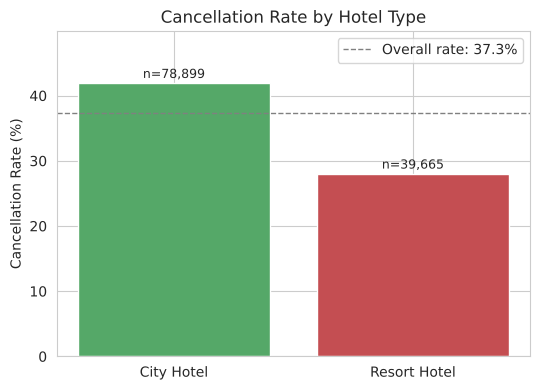

In [2]:
rate_by_hotel = df.groupby("hotel")["is_canceled"].agg(mean="mean", count="count")
rate_by_hotel["mean_pct"] = rate_by_hotel["mean"] * 100
overall_rate = df["is_canceled"].mean() * 100

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(rate_by_hotel.index, rate_by_hotel["mean_pct"], color=["#55A868", "#C44E52"])
for bar, n in zip(bars, rate_by_hotel["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
             f"n={n:,}", ha="center", fontsize=9)
ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1,
           label=f"Overall rate: {overall_rate:.1f}%")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_title("Cancellation Rate by Hotel Type")
ax.set_ylim(0, max(rate_by_hotel["mean_pct"]) + 8)
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "01_cancellation_by_hotel.png")
plt.show()

print(rate_by_hotel.round(3))

## 2. Continuous features vs. cancellation status

Five numerical features are compared between canceled and non-canceled
bookings: `lead_time`, `adr`, `total_nights`, `total_guests`,
`previous_cancellations`. Two views are shown: boxplots and density (KDE)
plots. In both, the extreme tail is clipped **for display only** (axis
limits / 99th-percentile trim) - the underlying data used for the
statistics is not modified here. Outlier capping for modeling purposes is
handled separately in the clustering notebook (B02), using rules derived
from the training set only.

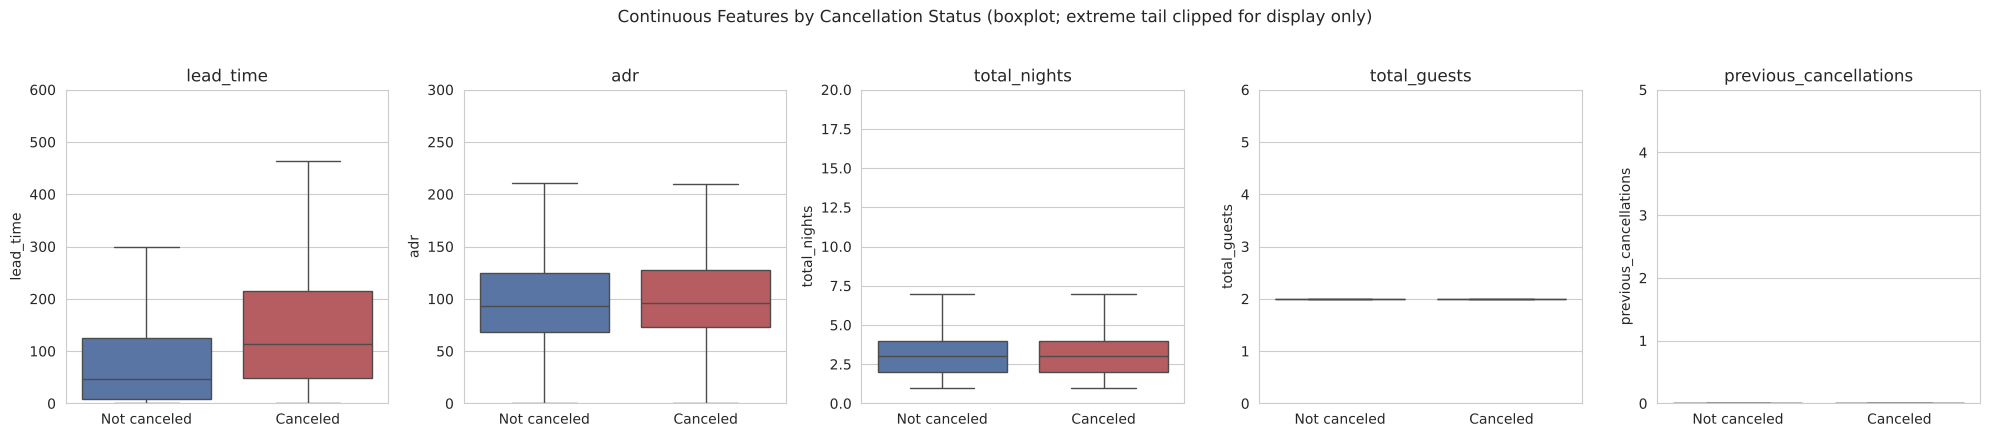

In [3]:
cont_features = ["lead_time", "adr", "total_nights", "total_guests", "previous_cancellations"]
display_ylim = {
    "lead_time": (0, 600), "adr": (0, 300), "total_nights": (0, 20),
    "total_guests": (0, 6), "previous_cancellations": (0, 5),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
for ax, feat in zip(axes, cont_features):
    sns.boxplot(data=df, x="is_canceled", y=feat, hue="is_canceled",
                palette=PALETTE, legend=False, showfliers=False, ax=ax)
    ax.set_ylim(display_ylim[feat])
    ax.set_xlabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Not canceled", "Canceled"])
    ax.set_title(feat)
fig.suptitle("Continuous Features by Cancellation Status (boxplot; extreme tail clipped for display only)", y=1.03)
plt.tight_layout()
plt.savefig(fig_dir / "02_continuous_boxplots.png", bbox_inches="tight")
plt.show()

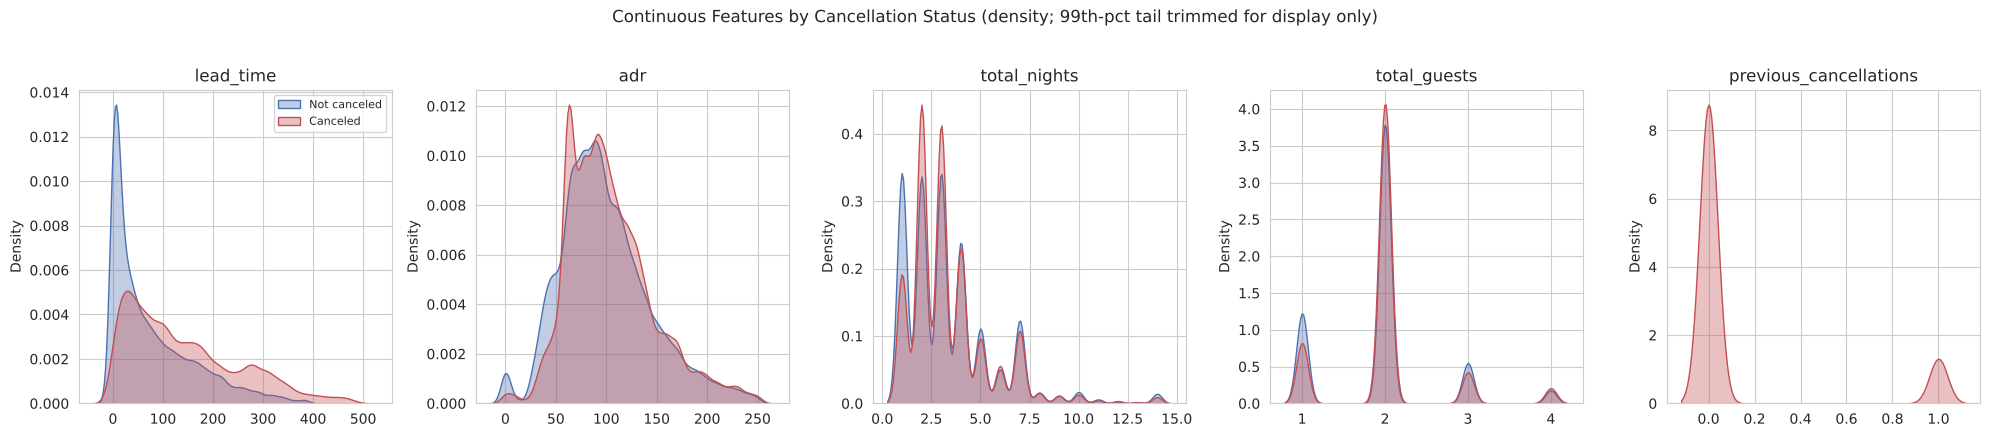

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
for ax, feat in zip(axes, cont_features):
    for label, color in PALETTE.items():
        subset = df.loc[df["is_canceled"] == label, feat]
        subset = subset[subset <= subset.quantile(0.99)]
        sns.kdeplot(subset, fill=True, alpha=0.35, color=color, ax=ax,
                    label="Canceled" if label == 1 else "Not canceled")
    ax.set_title(feat)
    ax.set_xlabel("")
axes[0].legend(fontsize=8)
fig.suptitle("Continuous Features by Cancellation Status (density; 99th-pct tail trimmed for display only)", y=1.03)
plt.tight_layout()
plt.savefig(fig_dir / "02b_continuous_kde.png", bbox_inches="tight")
plt.show()

### Note on outliers (numerical variables)

Per the experiment plan, distributions and outliers in the numerical
variables are examined here. A's cleaning step already removed clearly
invalid rows (negative ADR, zero guests, zero nights); the summary below
shows what remains - the long right tails that are real but extreme (e.g.
`adr` up to 5,400 vs a median of 95; `total_guests` up to 55 vs a median of
2). These are not further modified in this EDA notebook; outlier capping
is applied separately and only for clustering inputs in `B_02_Clustering.ipynb`,
using thresholds derived from the training set.

In [5]:
print(df[cont_features].describe().round(1))

       lead_time       adr  total_nights  total_guests  previous_cancellations
count   118564.0  118564.0      118564.0      118564.0                118564.0
mean       104.5     102.5           3.4           2.0                     0.1
std        106.9      50.0           2.5           0.7                     0.8
min          0.0       0.0           1.0           1.0                     0.0
25%         18.0      70.0           2.0           2.0                     0.0
50%         70.0      95.0           3.0           2.0                     0.0
75%        161.0     126.0           4.0           2.0                     0.0
max        709.0    5400.0          69.0          55.0                    26.0


## 3. Categorical features: cancellation rate by group (with sample size)

Per the team's agreement, every bar is annotated with its sample size `n`
so a high/low rate from a tiny category is not mistaken for a strong,
reliable pattern.

--- market_segment ---
                 mean  count
market_segment              
Undefined       1.000      2
Groups          0.612  19758
Online TA       0.369  56129
Offline TA/TO   0.345  24049
Aviation        0.221    231
Corporate       0.189   5231
Direct          0.155  12449
Complementary   0.122    715

--- distribution_channel ---
                       mean  count
distribution_channel              
Undefined             0.800      5
TA/TO                 0.412  97335
Corporate             0.222   6584
GDS                   0.195    190
Direct                0.176  14450

--- deposit_type ---
               mean   count
deposit_type               
Non Refund    0.994   14587
No Deposit    0.286  103815
Refundable    0.222     162

--- customer_type ---
                  mean  count
customer_type                
Transient        0.410  88935
Contract         0.311   4056
Transient-Party  0.255  25004
Group            0.102    569

--- is_repeated_guest ---
                    

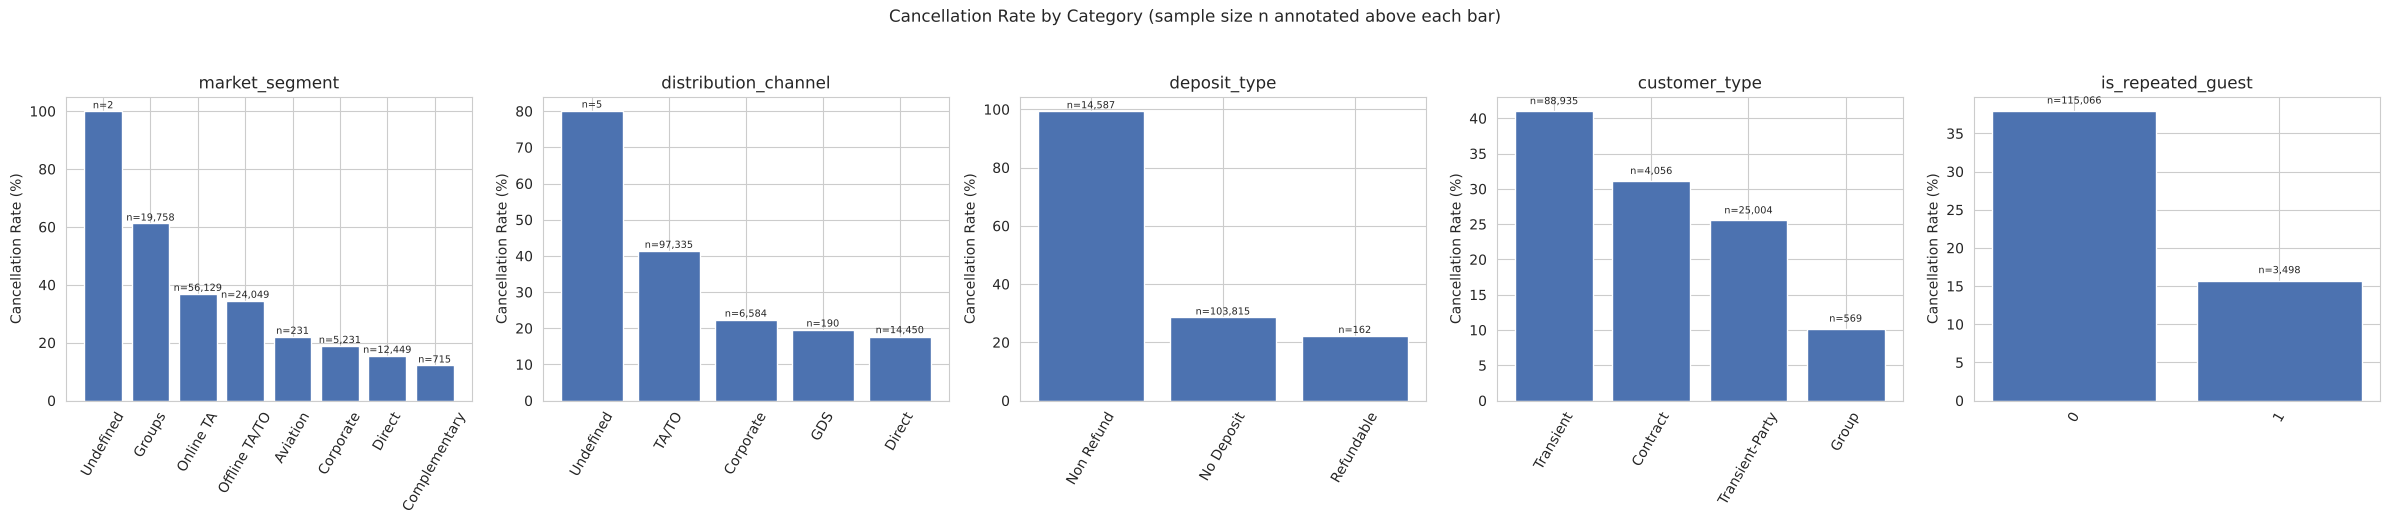

In [6]:
cat_features = ["market_segment", "distribution_channel", "deposit_type", "customer_type", "is_repeated_guest"]

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, feat in zip(axes, cat_features):
    g = df.groupby(feat)["is_canceled"].agg(mean="mean", count="count").sort_values("mean", ascending=False)
    g["mean_pct"] = g["mean"] * 100
    bars = ax.bar(g.index.astype(str), g["mean_pct"], color="#4C72B0")
    for bar, n in zip(bars, g["count"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f"n={n:,}", ha="center", fontsize=7)
    ax.set_title(feat)
    ax.set_ylabel("Cancellation Rate (%)")
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Cancellation Rate by Category (sample size n annotated above each bar)", y=1.04)
plt.tight_layout()
plt.savefig(fig_dir / "03_categorical_cancellation_rate.png", bbox_inches="tight")
plt.show()

for feat in cat_features:
    g = df.groupby(feat)["is_canceled"].agg(mean="mean", count="count").sort_values("mean", ascending=False)
    print(f"--- {feat} ---")
    print(g.round(3))
    print()

**Note on `deposit_type`**: `Non Refund` bookings show a 99.4% cancellation
rate (n=14,587 - not a small-sample artifact). This is the opposite of the
typical real-world expectation that a non-refundable deposit discourages
cancellation, so it is worth flagging explicitly in the report rather than
reading it as a causal business insight - this analysis only establishes
the observed association, not why `Non Refund` bookings cancel at this
rate in this particular dataset.

**Note on small samples**: `market_segment = Undefined` (n=2) and
`distribution_channel = Undefined` (n=5) show 100%/80% cancellation purely
because of tiny sample size - exactly the kind of misleading case the n
annotation is meant to catch. These should be excluded or footnoted rather
than discussed as real patterns.

## 4. Seasonal / monthly pattern

                     mean  count  mean_pct
arrival_date_month                        
January             0.307   5871    30.710
February            0.336   7998    33.583
March               0.324   9715    32.383
April               0.409  11045    40.878
May                 0.399  11704    39.944
June                0.416  10891    41.612
July                0.376  12586    37.629
August              0.379  13812    37.916
September           0.393  10477    39.267
October             0.384  11064    38.368
November            0.316   6712    31.585
December            0.354   6689    35.386

--- arrival_season ---
                 mean  count
arrival_season              
Spring          0.380  32464
Summer          0.389  37289
Autumn          0.371  28253
Winter          0.333  20558

Years of data covered per month (uneven - see note below):
arrival_date_month
January            [2016, 2017]
February           [2016, 2017]
March              [2016, 2017]
April              [2016,

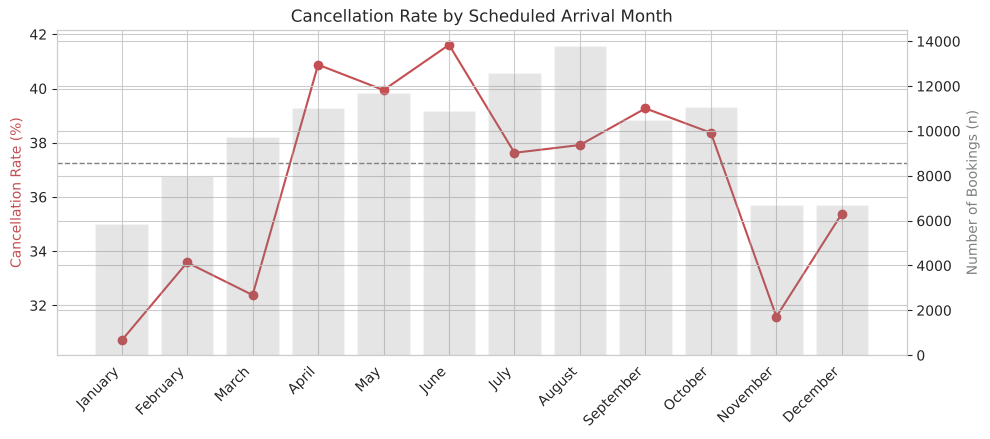

In [7]:
month_order = ["January","February","March","April","May","June","July",
                "August","September","October","November","December"]
monthly = df.groupby("arrival_date_month")["is_canceled"].agg(mean="mean", count="count").reindex(month_order)
monthly["mean_pct"] = monthly["mean"] * 100

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(monthly.index, monthly["mean_pct"], marker="o", color="#C44E52", label="Cancellation rate")
ax1.set_ylabel("Cancellation Rate (%)", color="#C44E52")
ax1.set_xticks(range(len(month_order)))
ax1.set_xticklabels(month_order, rotation=45, ha="right")
ax1.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)

ax2 = ax1.twinx()
ax2.bar(monthly.index, monthly["count"], alpha=0.2, color="gray", label="Bookings (n)")
ax2.set_ylabel("Number of Bookings (n)", color="gray")
ax1.set_title("Cancellation Rate by Scheduled Arrival Month")
plt.tight_layout()
plt.savefig(fig_dir / "04_monthly_trend.png")
plt.show()

print(monthly.round(3))

season_order = ["Spring","Summer","Autumn","Winter"]
season = df.groupby("arrival_season")["is_canceled"].agg(mean="mean", count="count").reindex(season_order)
print("\n--- arrival_season ---")
print(season.round(3))

print("\nYears of data covered per month (uneven - see note below):")
print(df.groupby("arrival_date_month")["arrival_date_year"].unique().reindex(month_order))

**Note on year coverage**: the booking-count bars above are not on an
equal footing across months. July and August have three years of data
(2015-2017); January-June have two years, but 2016-2017 (not 2015); and
September-December also have two years, but 2015-2016 (not 2017) - the
dataset's collection window starts mid-2015 and ends in mid-2017, so the
months at each end simply have fewer years represented. This means the
monthly *booking-count* comparison is partly an artefact of how many years
each month was sampled, not purely a seasonal signal - a month with 3
years of data is expected to show roughly 50% more bookings than one with
2, independent of any real seasonal popularity. The *cancellation-rate*
line is less affected (it's an average, not a count), but should still be
read as a rate over an uneven sample rather than evidence of a stable
year-over-year seasonal pattern.

## 5. Quantitative summary: correlation with `is_canceled`

Numeric features plus one-hot-encoded categorical features are ranked by
their absolute correlation with the target, mirroring the approach from the
course's EDA lecture notebook (`numeric_cols.corr()['target']` /
`dummy_df.corr()['target']`), adapted here for a binary target instead of a
continuous one.

                      feature  correlation_with_is_canceled
      deposit_type_Non Refund                         0.481
      deposit_type_No Deposit                        -0.478
                    lead_time                         0.292
     lead_time_group_0-7 days                        -0.251
    total_of_special_requests                        -0.236
        market_segment_Groups                         0.221
    lead_time_group_181+ days                         0.210
  required_car_parking_spaces                        -0.197
   distribution_channel_TA/TO                         0.175
        market_segment_Direct                        -0.154
  distribution_channel_Direct                        -0.151
             hotel_City Hotel                         0.136
           hotel_Resort Hotel                        -0.136
      customer_type_Transient                         0.134
customer_type_Transient-Party                        -0.125
       previous_cancellations           

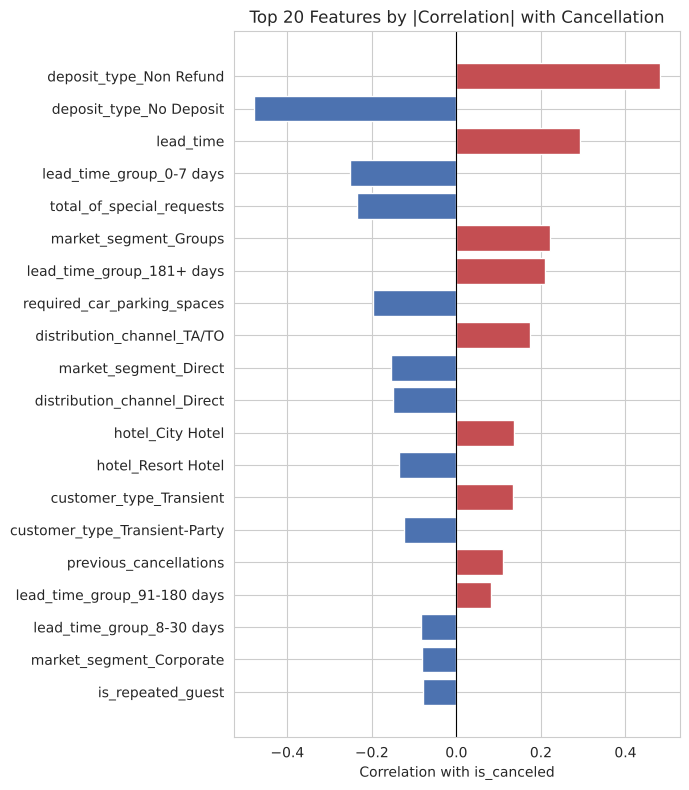

In [8]:
numeric_cols = ["lead_time", "total_nights", "total_guests", "adr",
                 "previous_cancellations", "previous_bookings_not_canceled",
                 "is_repeated_guest", "total_of_special_requests",
                 "required_car_parking_spaces", "family_booking"]
cat_cols_for_corr = ["hotel", "market_segment", "distribution_channel",
                      "deposit_type", "customer_type", "meal",
                      "reserved_room_type", "lead_time_group", "arrival_season"]

corr_base = df[numeric_cols + ["is_canceled"]].copy()
dummy_df = pd.get_dummies(df[cat_cols_for_corr], drop_first=False)
full_corr_df = pd.concat([corr_base, dummy_df], axis=1)

corr_with_target = full_corr_df.corr(numeric_only=True)["is_canceled"].drop("is_canceled")
corr_with_target = corr_with_target.sort_values(key=lambda s: s.abs(), ascending=False)

corr_table = corr_with_target.round(3).reset_index()
corr_table.columns = ["feature", "correlation_with_is_canceled"]
corr_table.to_csv(tab_dir / "05_correlation_with_target.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 8))
top_n = corr_table.head(20)
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top_n["correlation_with_is_canceled"]]
ax.barh(top_n["feature"][::-1], top_n["correlation_with_is_canceled"][::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with is_canceled")
ax.set_title("Top 20 Features by |Correlation| with Cancellation")
plt.tight_layout()
plt.savefig(fig_dir / "05_correlation_barh.png")
plt.show()

print(corr_table.head(20).to_string(index=False))

**Note on field availability**: this ranking includes fields A's data
dictionary marks `Excluded` from the primary classification template, with
a note to verify their availability at initial booking before final
modelling (`deposit_type`, `customer_type`, `adr`, `required_car_parking_spaces`,
`total_of_special_requests`). That is not a mistake here - the proposal
asks for these fields to be analysed, and this is EDA, not the primary
classification model. But the ranking above is only a **descriptive**
association between each field's recorded value and the cancellation
outcome; it does not show that a field is available at the moment a
booking is first made, and it should not be read as evidence that a
field is safe to use for real-time prediction or intervention. If a
classification notebook (C/D/E) wants to pick up a highly-ranked field
here, or use it to set a feature or threshold, that needs A's
confirmation of its initial-booking-time availability first - "it showed
a strong correlation in B's EDA" is not enough on its own. This ranking
is also computed on the full cleaned dataset (train + test combined), so
it is a descriptive summary, not a method-selection step; this
notebook's full-data EDA is not used for method selection anywhere in
the project, and the one method-selection decision made in *this*
notebook pair that depends on avoiding test-set leakage - choosing k for
B_02's clustering - is computed on the training set only (see
`B_02_Clustering.ipynb`). This availability caveat is separate from, and
does not get resolved by, confirming a field's initial-booking-time
availability with A: even a confirmed-available field still should not
be chosen as a classification feature, threshold, or hyperparameter
based on an EDA ranking computed over the test set.

## 6. Robustness check: do the top patterns hold in both hotel types?

The proposal's risk-management plan notes that this dataset covers only one
resort hotel and one city hotel, and commits to reporting results
separately for the two hotels rather than generalising a pooled finding to
"hotels" in general. The two strongest correlates found in Section 5
(`deposit_type` and `lead_time`) are checked here within each hotel type,
so the pooled EDA findings above are not assumed to transfer uniformly
across the two hotels.

In [9]:
print("Cancellation rate by deposit_type, split by hotel:")
print(df.groupby(["hotel", "deposit_type"])["is_canceled"].agg(mean="mean", count="count").round(3))

print("\nCancellation rate by lead_time_group, split by hotel:")
print(df.groupby(["hotel", "lead_time_group"], observed=True)["is_canceled"].agg(mean="mean", count="count").round(3))

Cancellation rate by deposit_type, split by hotel:
                            mean  count
hotel        deposit_type              
City Hotel   No Deposit    0.306  66011
             Non Refund    0.998  12868
             Refundable    0.700     20
Resort Hotel No Deposit    0.250  37804
             Non Refund    0.960   1719
             Refundable    0.155    142

Cancellation rate by lead_time_group, split by hotel:
                               mean  count
hotel        lead_time_group              
City Hotel   0-7 days         0.123  10511
             181+ days        0.641  16929
             31-90 days       0.400  20748
             8-30 days        0.310  12511
             91-180 days      0.480  18200
Resort Hotel 0-7 days         0.066   8735
             181+ days        0.417   7720
             31-90 days       0.327   8689
             8-30 days        0.221   6337
             91-180 days      0.376   8184


**Finding**: the direction of both patterns holds in both hotels (Non
Refund bookings and longer lead times both show much higher cancellation
in City Hotel and in Resort Hotel separately), but the City Hotel's rates
run consistently higher than Resort Hotel's at every level - consistent
with the overall 41.9% vs 28.0% gap from Section 1. This supports treating
the patterns as real rather than an artefact of pooling two different
hotels, while still noting the absolute rates should not be generalised
beyond these two properties, per the proposal's limitations section.

## Summary of EDA findings

- Overall cancellation rate: 37.26% (118,564 cleaned bookings). City Hotel
  (41.9%) cancels noticeably more than Resort Hotel (28.0%).
- `deposit_type = Non Refund` and `lead_time` are the strongest correlates
  of cancellation (|r| ~0.48 and 0.29 respectively); `Non Refund`'s extreme
  rate is a known dataset quirk, not necessarily a causal driver.
- Longer lead time, group/online-TA bookings, and transient customer type
  are consistently associated with higher cancellation; direct bookings and
  repeat guests cancel less.
- A handful of categories (e.g. `Undefined` segments) have very few
  bookings and should not be over-interpreted despite extreme rates - this
  is why every categorical chart here reports n alongside the rate.
- Candidate final-report charts (~4-5, to be finalized after review):
  hotel-type rate, the continuous-feature panel (or a condensed version),
  the categorical rate panel (or a subset), and the correlation summary.
